# Airbnb Open Data — Deep EDA, Price Drivers & Price Prediction

**Term-paper project | Sameer Ansari | B.Tech CSE | Guru Gobind Singh Indraprastha University**

**Main research questions:**
1. What do the NYC Airbnb listing prices look like, and how reliable is the dataset?
2. **Which observed property characteristics are associated with price, and how large are these differences?**
3. Do room type, borough, cancellation policy and other characteristics have significant or practically meaningful associations with price?
4. Can we **predict advertised listing price** from information available about a listing, without leaking the answer through `service_fee`?
5. Which input features does the trained model rely on, and is that reliance stable or actually useful?

**Contents:** Dataset quality → price distribution → room/borough/neighborhood patterns → policy/review comparisons → statistical tests → **price-driver scorecards, within-borough comparisons and numerical-feature bins** → train/test regression models → **held-out permutation feature importance** → sample predictions → discussion and recommendations.

**What the model predicts:** a listing's *advertised price* (`price`, in the dataset's currency). It does **not** predict revenue, occupancy, booked price, future price movements, or profit.

**Caution:** The supplied dataset has no independently verified origin/date or detailed amenities, capacity, bedrooms, bathrooms or transaction history. Observed price differences and model reliance on a feature do **not** prove causal effects. The model should not be treated as a professional pricing system unless external validation shows meaningful accuracy.


## 0. Setup and reproducibility

**Run in order from the top.** Keep the Excel workbook alongside this notebook in Jupyter, or upload it in Colab. For Google Colab, when the file is missing, the next cell opens a file-upload prompt. Charts and tables are generated from the real dataset; numbers are not hardcoded.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from scipy.stats import kruskal, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             median_absolute_error, r2_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 5)
print("Libraries imported. Random seed:", RANDOM_STATE)

Libraries imported. Random seed: 42


In [2]:
# Search common notebook / Colab file locations. Use a path relative to the notebook where possible.
file_name = "Airbnb_Open_Data.xlsx"
candidates = [Path(file_name), Path.cwd()/file_name,
              Path("/content")/file_name, Path("/mnt/data")/file_name]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    try:
        from google.colab import files
        print("Upload Airbnb_Open_Data.xlsx in the file chooser:")
        files.upload()
        data_path = Path(file_name)
    except ImportError:
        pass
if data_path is None or not data_path.exists():
    raise FileNotFoundError("Place Airbnb_Open_Data.xlsx next to this notebook, then rerun this cell.")

# Full Excel import can take some time: the supplied workbook has over 100,000 records.
df_raw = pd.read_excel(data_path)
print("Loaded file:", data_path.name)
print("Original shape:", df_raw.shape)
display(df_raw.head(5))

Loaded file: Airbnb_Open_Data.xlsx
Original shape: (102599, 26)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,country code,instant_bookable,cancellation_policy,room type,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,US,0.0,strict,Private room,2020.0,966.0,193.0,10.0,9.0,2021-10-19,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,US,0.0,moderate,Entire home/apt,2007.0,142.0,28.0,30.0,45.0,2022-05-21,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,US,1.0,flexible,Private room,2005.0,620.0,124.0,3.0,0.0,NaT,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,US,1.0,moderate,Entire home/apt,2005.0,368.0,74.0,30.0,270.0,2019-07-05,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,US,0.0,moderate,Entire home/apt,2009.0,204.0,41.0,10.0,9.0,2018-11-19,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


## 1. Understand the dataset — questions before calculations

This is a **New York City listing-level** dataset (boroughs, neighborhood coordinates, rooms and host attributes). A row describes a listing; it is not an individual reservation or nightly transaction. Review and availability columns are snapshots and should not be interpreted as confirmed occupancy.

We first audit column types, missingness, duplicate rows, IDs and valid category values before changing any records.

In [3]:
print("Original columns:")
print(df_raw.columns.tolist())
print("\nColumn types:")
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
                      "missing_count": df_raw.isna().sum(),
                      "missing_%": (100 * df_raw.isna().mean()).round(2),
                      "unique_nonmissing": df_raw.nunique(dropna=True)}).sort_values("missing_%", ascending=False))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print("Repeated listing IDs:", int(df_raw["id"].duplicated().sum()) if "id" in df_raw else "ID column unavailable")

Original columns:
['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']

Column types:


,dtype,missing_count,missing_%,unique_nonmissing
license,object,102597,100.00,1
house_rules,object,54843,53.45,1975
last review,datetime64[ns],15893,15.49,2477
reviews per month,float64,15879,15.48,1016
country,object,532,0.52,1
availability 365,float64,448,0.44,438
minimum nights,float64,409,0.40,153
host name,object,408,0.40,13189
review rate number,float64,326,0.32,5
calculated host listings count,float64,319,0.31,78


Exact duplicate rows: 541
Repeated listing IDs: 541


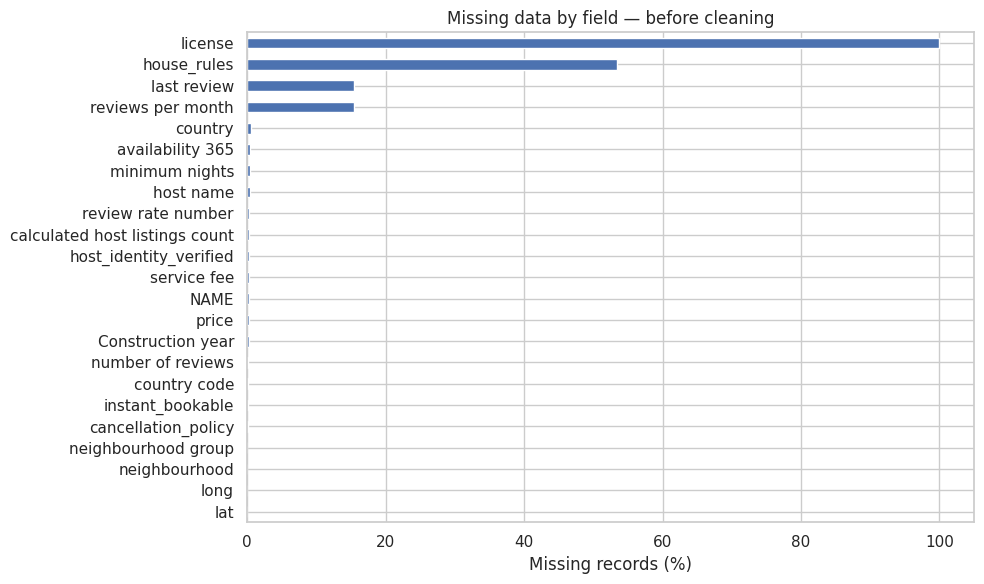

Fields that are almost entirely missing should not be used as modelling predictors.


In [4]:
missing_before = (df_raw.isna().mean()*100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
missing_before[missing_before > 0].plot(kind="barh", ax=ax)
ax.invert_yaxis(); ax.set_title("Missing data by field — before cleaning")
ax.set_xlabel("Missing records (%)"); plt.tight_layout(); plt.show()
print("Fields that are almost entirely missing should not be used as modelling predictors.")

## 2. Cleaning, validation and data dictionary

We remove **exact duplicate rows**. Missing values are **not silently filled**: for descriptive analysis, aggregations use the observed records; for modelling, missing predictors are imputed using statistics learnt **on training data only**. Listings without a valid price are excluded from the price-specific analysis and model, not from the initial dataset audit.

`availability_365` is a bounded count (0–365), and `minimum_nights` must be positive. Values outside those limits are set to missing rather than treated as valid. Dates are kept as dates; nonexistent reviews are not fabricated.

In [5]:
import re

df = df_raw.copy()
df.columns = [re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")
              for c in df.columns]
rows_original = len(df)
df = df.drop_duplicates().copy()
rows_unique = len(df)

text_columns = ["name", "host_identity_verified", "host_name", "neighbourhood_group",
                "neighbourhood", "country", "country_code", "cancellation_policy",
                "room_type", "house_rules", "license"]
for c in text_columns:
    if c in df:
        df[c] = df[c].astype("string").str.strip()
        df[c] = df[c].replace("", pd.NA)

# Known spelling inconsistencies in the borough field.
if "neighbourhood_group" in df:
    df["neighbourhood_group"] = df["neighbourhood_group"].replace(
        {"brookln": "Brooklyn", "manhatan": "Manhattan"})

# Compatible with both Excel numeric currency and text such as '$1,200'.
for c in ["price", "service_fee"]:
    if c in df:
        df[c] = pd.to_numeric(df[c].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")

numeric_fields = ["lat", "long", "construction_year", "minimum_nights", "number_of_reviews",
                  "reviews_per_month", "review_rate_number", "calculated_host_listings_count",
                  "availability_365", "instant_bookable"]
for c in numeric_fields:
    if c in df:
        df[c] = pd.to_numeric(df[c], errors="coerce")
if "last_review" in df:
    df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")

# Audit raw invalid values before replacing them with NA.
invalid_counts = {
    "non_positive_price": int(df["price"].notna().sum() - df["price"].gt(0).sum()),
    "minimum_nights_outside_1_to_365": int((df["minimum_nights"].notna() & ~df["minimum_nights"].between(1,365)).sum()),
    "availability_outside_0_to_365": int((df["availability_365"].notna() & ~df["availability_365"].between(0,365)).sum()),
    "construction_year_outside_1800_to_2026": int((df["construction_year"].notna() & ~df["construction_year"].between(1800,2026)).sum()),
}
for c, low, high in [("minimum_nights", 1, 365), ("availability_365", 0, 365),
                     ("construction_year", 1800, 2026), ("lat", -90, 90), ("long", -180, 180)]:
    if c in df:
        df.loc[~df[c].between(low, high), c] = np.nan

df["price"] = df["price"].where(df["price"] > 0)
df_clean = df.copy()
eda = df_clean.dropna(subset=["price"]).copy()

print("Source rows:", rows_original)
print("Removed exact duplicates:", rows_original - rows_unique)
print("Unique records retained:", rows_unique)
print("Records with a usable price:", len(eda))
print("\nInvalid values identified in distinct checks:")
display(pd.Series(invalid_counts, name="count").to_frame())
print("\nRemaining missing entries by column (top 12):")
display(df_clean.isna().sum().sort_values(ascending=False).head(12).to_frame("missing"))

Source rows: 102599
Removed exact duplicates: 541
Unique records retained: 102058
Records with a usable price: 101811

Invalid values identified in distinct checks:


,count
non_positive_price,0
minimum_nights_outside_1_to_365,48
availability_outside_0_to_365,3185
construction_year_outside_1800_to_2026,0



Remaining missing entries by column (top 12):


,missing
license,102056
house_rules,54538
last_review,15832
reviews_per_month,15818
availability_365,3633
country,532
minimum_nights,448
host_name,406
calculated_host_listings_count,319
review_rate_number,319


In [6]:
dictionary = pd.DataFrame([
    ("id, host_id", "Identifiers — NOT model predictors"),
    ("neighbourhood_group, neighbourhood, lat, long", "Listing location"),
    ("room_type, construction_year, minimum_nights", "Property attributes and policy"),
    ("host_identity_verified, instant_bookable, cancellation_policy", "Host / booking settings"),
    ("price", "Prediction target: advertised listing price (not revenue)"),
    ("service_fee", "Highly dependent on price; EXCLUDED to prevent leakage"),
    ("number_of_reviews, reviews_per_month, last_review", "Review activity snapshot; EDA only"),
    ("review_rate_number", "Review rating; EDA only"),
    ("availability_365", "Availability snapshot; NOT booked nights or occupancy"),
    ("license, house_rules, name, host_name", "Sparse / free text / identifier-like; excluded from baseline model"),
], columns=["Columns", "Meaning / analytical use"])
display(dictionary)
print("Room types:", df_clean["room_type"].dropna().unique().tolist())
print("Boroughs:", df_clean["neighbourhood_group"].dropna().unique().tolist())
print("Duplicate listing IDs after exact-row deduplication:", int(df_clean["id"].duplicated().sum()))

,Columns,Meaning / analytical use
0,"id, host_id",Identifiers — NOT model predictors
1,"neighbourhood_group, neighbourhood, lat, long",Listing location
2,"room_type, construction_year, minimum_nights",Property attributes and policy
3,"host_identity_verified, instant_bookable, canc...",Host / booking settings
4,price,Prediction target: advertised listing price (n...
5,service_fee,Highly dependent on price; EXCLUDED to prevent...
6,"number_of_reviews, reviews_per_month, last_review",Review activity snapshot; EDA only
7,review_rate_number,Review rating; EDA only
8,availability_365,Availability snapshot; NOT booked nights or oc...
9,"license, house_rules, name, host_name",Sparse / free text / identifier-like; excluded...


Room types: ['Private room', 'Entire home/apt', 'Shared room', 'Hotel room']
Boroughs: ['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
Duplicate listing IDs after exact-row deduplication: 0


## 3. Univariate EDA — price distribution and listing mix

The price variable is the target for regression, so understanding its support, skewness and extreme values is essential before selecting metrics or modelling. Prices are displayed in the numeric units provided in the workbook (USD is presumed for NYC, but the file itself does not prove a currency conversion rate).

,price
count,101811.0
mean,625.35558
std,331.672649
min,50.0
1%,61.0
5%,108.0
10%,165.0
25%,340.0
50%,625.0
75%,913.0


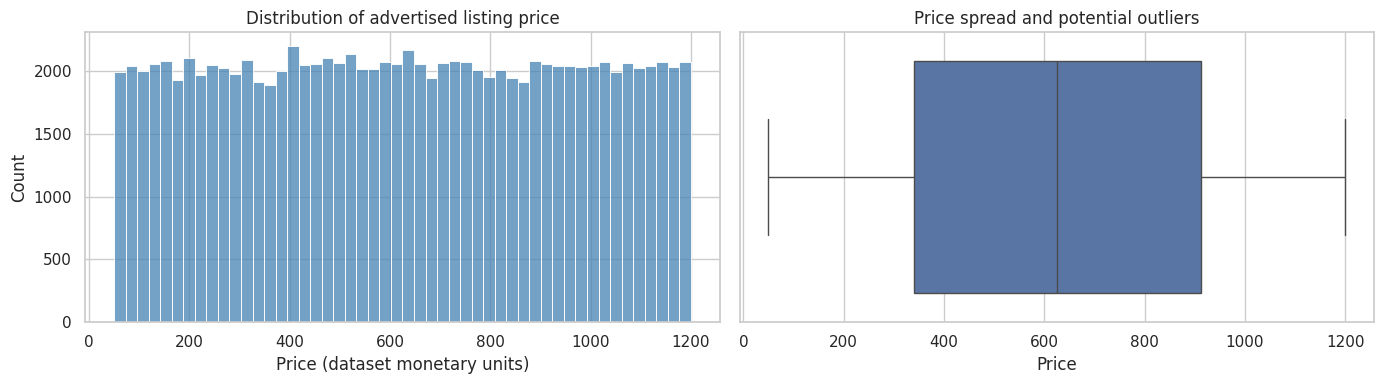

In [7]:
display(eda["price"].describe(percentiles=[.01,.05,.10,.25,.5,.75,.90,.95,.99]).to_frame("price"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(eda["price"], bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of advertised listing price")
axes[0].set_xlabel("Price (dataset monetary units)")
sns.boxplot(x=eda["price"], ax=axes[1])
axes[1].set_title("Price spread and potential outliers")
axes[1].set_xlabel("Price")
plt.tight_layout(); plt.show()

,listings,median_price,mean_price
room_type,,,
Entire home/apt,53296,624.0,625.24
Private room,46200,623.0,624.94
Shared room,2200,651.5,634.83
Hotel room,115,643.0,666.39


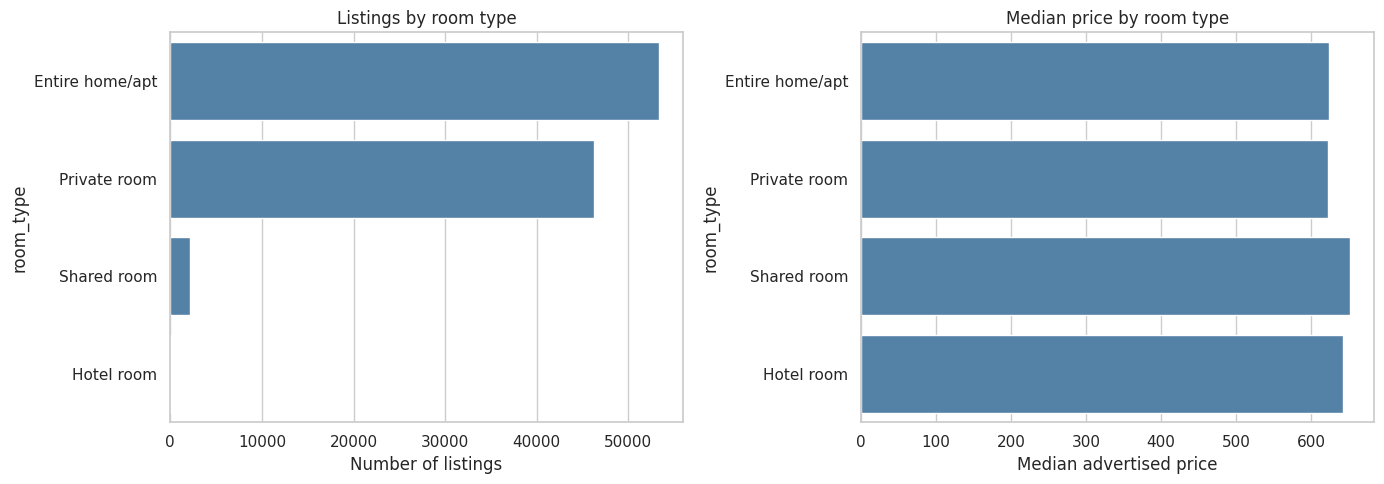

In [8]:
room = (eda.groupby("room_type", dropna=False)["price"]
        .agg(listings="size", median_price="median", mean_price="mean")
        .sort_values("listings", ascending=False))
display(room.round(2))
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.countplot(data=eda, y="room_type", order=room.index.dropna(), ax=axes[0], color="steelblue")
axes[0].set_title("Listings by room type"); axes[0].set_xlabel("Number of listings")
sns.barplot(data=room.reset_index(), y="room_type", x="median_price", ax=axes[1], color="steelblue")
axes[1].set_title("Median price by room type"); axes[1].set_xlabel("Median advertised price")
plt.tight_layout(); plt.show()

## 4. Location and geographic comparisons

We compare borough and neighborhood level patterns using both **counts** and **medians**. A small neighborhood sample may have an unstable median, so the top-neighborhood ranking is filtered to groups with sufficient records. High-count groups are not automatically high-price groups.

,listings,median_price,mean_price,std_price
neighbourhood_group,,,,
Manhattan,43448,621.0,622.65,331.26
Brooklyn,41538,626.0,626.5,331.94
Queens,13164,628.0,630.22,334.15
Bronx,2687,632.0,627.76,323.81
Staten Island,946,628.0,623.99,325.78
<NA>,28,661.0,658.36,336.41


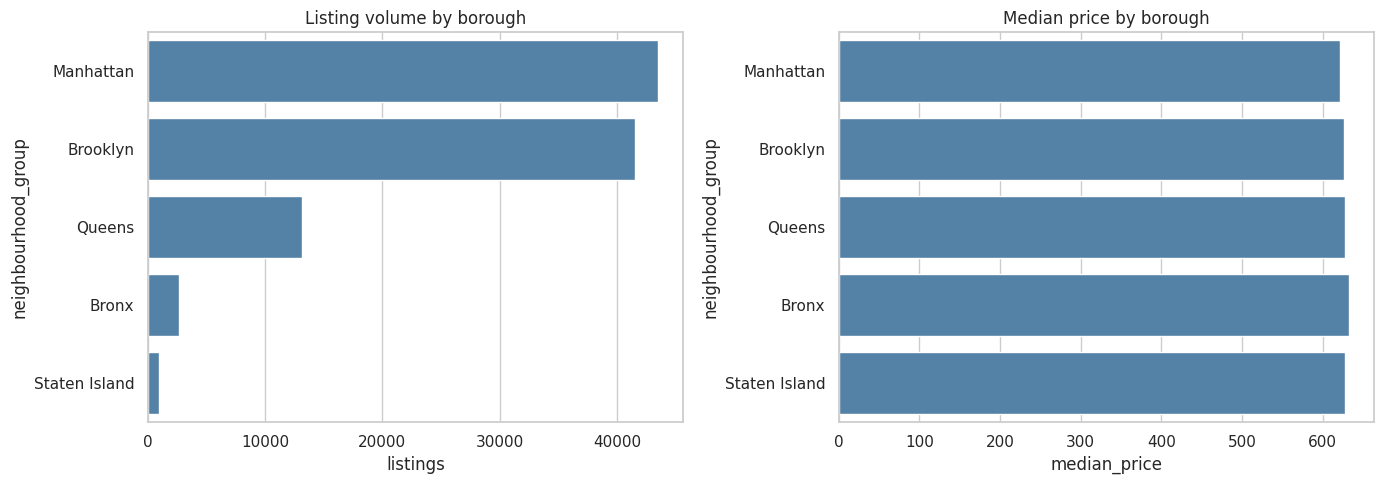

In [9]:
borough = (eda.groupby("neighbourhood_group", dropna=False)["price"]
           .agg(listings="size", median_price="median", mean_price="mean", std_price="std")
           .sort_values("listings", ascending=False))
display(borough.round(2))
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.barplot(data=borough.reset_index().dropna(subset=["neighbourhood_group"]),
            x="listings", y="neighbourhood_group", ax=axes[0], color="steelblue")
axes[0].set_title("Listing volume by borough")
sns.barplot(data=borough.reset_index().dropna(subset=["neighbourhood_group"]),
            x="median_price", y="neighbourhood_group", ax=axes[1], color="steelblue")
axes[1].set_title("Median price by borough")
plt.tight_layout();plt.show()

In [10]:
neigh = (eda.groupby(["neighbourhood_group", "neighbourhood"], dropna=True)
          .agg(listings=("price","size"), median_price=("price","median"))
          .sort_values("listings",ascending=False))
print("Most-represented neighborhoods:")
display(neigh.head(12).round(1))
min_n = 100
eligible_neigh = neigh.query("listings >= @min_n")
print(f"Neighborhoods with at least {min_n} priced listings:",len(eligible_neigh))
display(eligible_neigh.sort_values("median_price", ascending=False).head(12).round(1))

Most-represented neighborhoods:


listings  median_price
neighbourhood_group neighbourhood                             
Brooklyn            Bedford-Stuyvesant      7881         621.0
                    Williamsburg            7708         626.0
Manhattan           Harlem                  5428         620.0
Brooklyn            Bushwick                4937         640.0
Manhattan           Hell's Kitchen          3945         619.0
                    Upper West Side         3833         619.0
                    Upper East Side         3643         629.0
                    East Village            3457         616.0
                    Midtown                 3347         609.0
Brooklyn            Crown Heights           3241         618.0
Manhattan           East Harlem             2313         619.0
                    Chelsea                 2270         630.0

Neighborhoods with at least 100 priced listings: 102


/tmp/ipykernel_1233/3150445786.py:7: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  eligible_neigh = neigh.query("listings >= @min_n")


,,listings,median_price
neighbourhood_group,neighbourhood,,
Brooklyn,Gravesend,139,791.0
Queens,Ozone Park,150,734.0
Staten Island,St. George,125,732.0
Queens,Briarwood,119,732.0
Bronx,Longwood,133,714.0
Manhattan,NoHo,139,713.0
Bronx,Concourse,123,704.0
Brooklyn,Brownsville,153,689.0
Manhattan,Inwood,545,685.0


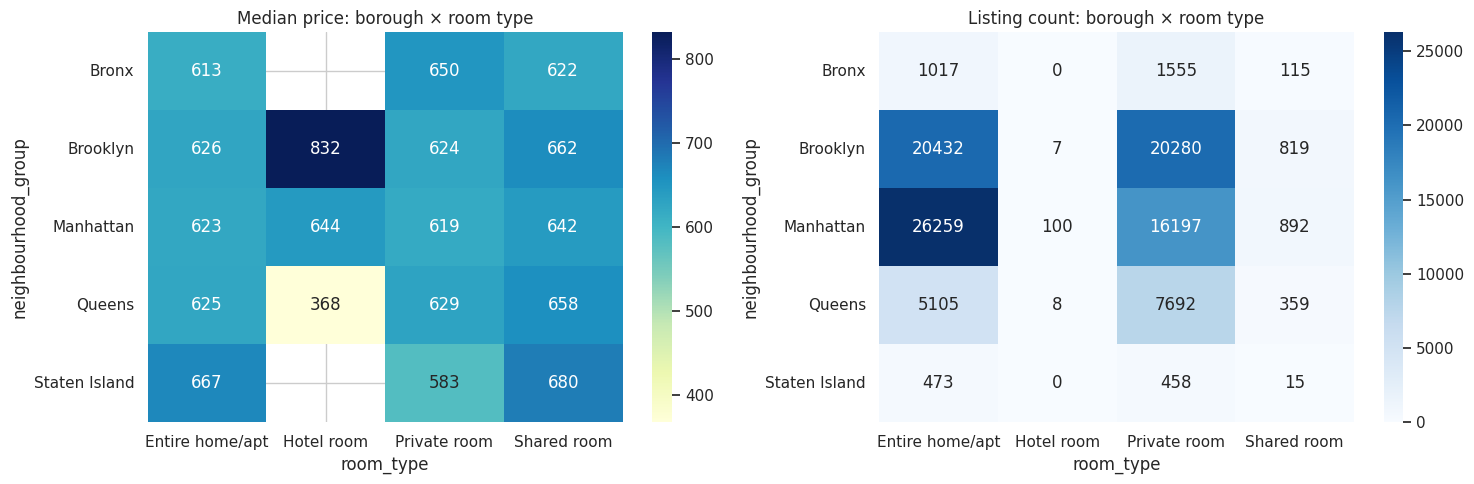

In [11]:
price_pivot = eda.pivot_table(index="neighbourhood_group",columns="room_type",values="price",aggfunc="median").astype(float)
count_pivot = eda.pivot_table(index="neighbourhood_group",columns="room_type",values="price",aggfunc="size",fill_value=0).astype(float)
fig, axes = plt.subplots(1,2,figsize=(15,5))
sns.heatmap(price_pivot,annot=True,fmt=".0f",cmap="YlGnBu",ax=axes[0])
axes[0].set_title("Median price: borough × room type")
sns.heatmap(count_pivot,annot=True,fmt=".0f",cmap="Blues",ax=axes[1])
axes[1].set_title("Listing count: borough × room type")
plt.tight_layout();plt.show()

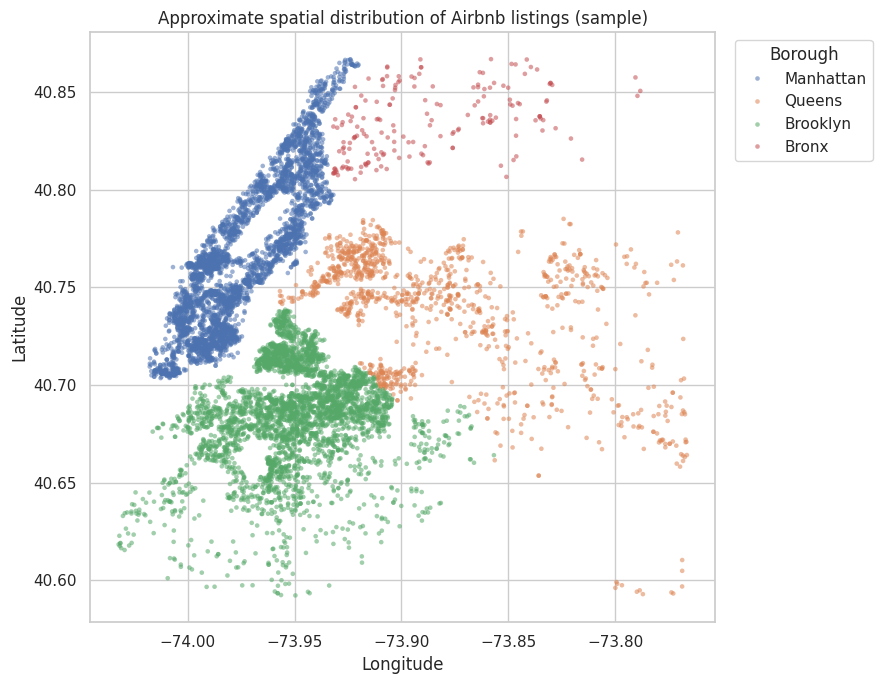

In [12]:
# Scatter map on NYC coordinates. The 1st–99th quantiles reduce visual distortion by anomalous coordinates.
geo = eda.dropna(subset=["lat","long","neighbourhood_group"]).copy()
geo = geo.loc[geo["lat"].between(geo["lat"].quantile(.01), geo["lat"].quantile(.99)) &
              geo["long"].between(geo["long"].quantile(.01), geo["long"].quantile(.99))]
geo_sample = geo.sample(n=min(9000,len(geo)),random_state=RANDOM_STATE)
fig,ax=plt.subplots(figsize=(9,7))
sns.scatterplot(data=geo_sample,x="long",y="lat",hue="neighbourhood_group",
                s=11,alpha=.55,linewidth=0,ax=ax)
ax.set_title("Approximate spatial distribution of Airbnb listings (sample)")
ax.set_xlabel("Longitude");ax.set_ylabel("Latitude")
ax.legend(title="Borough",bbox_to_anchor=(1.02,1),loc="upper left")
plt.tight_layout();plt.show()

## 5. Other listing characteristics, reviews and availability

Reviews and availability are descriptive signals, **not** proof of demand. In particular, `365 − availability_365` is *not* a valid occupancy estimate; unavailable days might reflect owner blocks, closed calendars or other factors.


 host_identity_verified


,listings,median_price,mean_price
host_identity_verified,,,
unconfirmed,50831,626.0,626.79
verified,50695,623.0,623.83
<NA>,285,656.0,640.87



 cancellation_policy


,listings,median_price,mean_price
cancellation_policy,,,
moderate,34085,622.0,625.21
strict,33847,625.0,624.59
flexible,33808,626.0,626.23
<NA>,71,693.0,645.14



 instant_bookable


,listings,median_price,mean_price
instant_bookable,,,
0.0,51066,626.0,625.18
1.0,50645,623.0,625.52
NaN,100,661.0,633.83


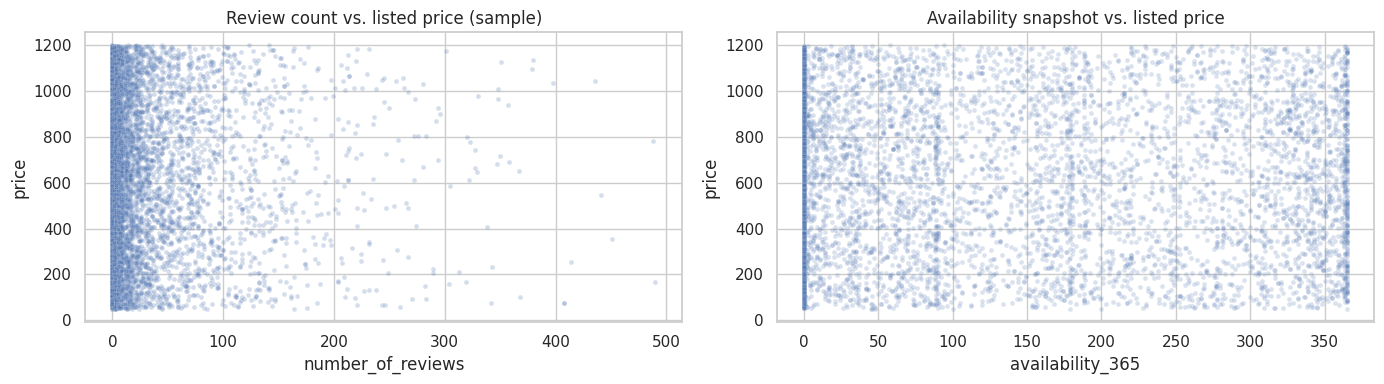

In [13]:
for field in ["host_identity_verified","cancellation_policy","instant_bookable"]:
    if field not in eda: continue
    grouped = (eda.groupby(field,dropna=False)["price"]
               .agg(listings="size",median_price="median",mean_price="mean")
               .sort_values("listings",ascending=False))
    print("\n",field)
    display(grouped.round(2))
fig,axes=plt.subplots(1,2,figsize=(14,4))
sample_reviews=eda.loc[eda["number_of_reviews"].between(0,500)].sample(n=min(7000, len(eda)),random_state=RANDOM_STATE)
sns.scatterplot(data=sample_reviews,x="number_of_reviews",y="price",alpha=.24,s=12,ax=axes[0])
axes[0].set_title("Review count vs. listed price (sample)")
valid_avail=eda.dropna(subset=["availability_365"])
sns.scatterplot(data=valid_avail.sample(n=min(7000,len(valid_avail)),random_state=RANDOM_STATE),
                x="availability_365",y="price",alpha=.20,s=12,ax=axes[1])
axes[1].set_title("Availability snapshot vs. listed price")
plt.tight_layout();plt.show()

Share of listings with a known last-review date: 84.5%
Recorded last-review date range: 2012-07-11 to 2058-06-16


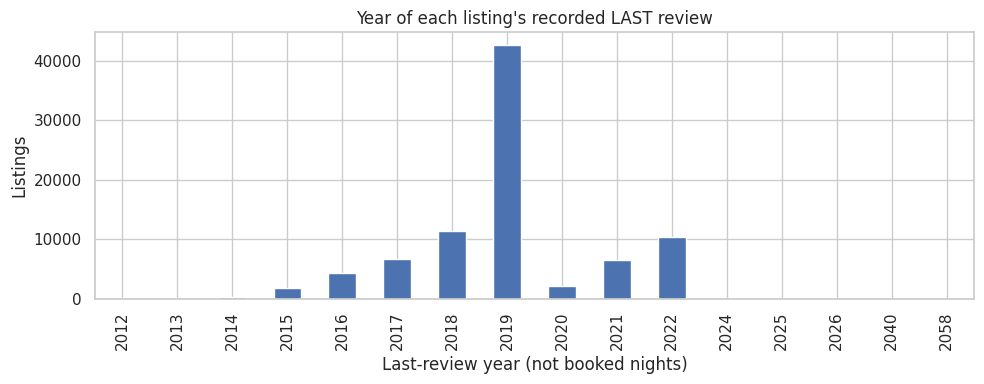

In [14]:
# Dates reflect recorded review dates; they are NOT a historical series of nightly listing prices.
if "last_review" in eda:
    reviewed = eda.loc[eda["last_review"].notna()].copy()
    print("Share of listings with a known last-review date:",f"{len(reviewed)/len(eda):.1%}")
    print("Recorded last-review date range:",reviewed["last_review"].min().date(),"to", reviewed["last_review"].max().date())
    review_years = reviewed["last_review"].dt.year.value_counts().sort_index()
    ax=review_years.plot(kind="bar",figsize=(10,4),title="Year of each listing's recorded LAST review")
    ax.set_xlabel("Last-review year (not booked nights)");ax.set_ylabel("Listings")
    plt.tight_layout();plt.show()

## 6. Relationships, leakage and hypothesis testing

A high correlation may be misleading when one variable is calculated from another. Here `service_fee` is approximately **20% of price**. It would be **target leakage** to use that fee as a feature for predicting price. Identifiers, listing names and post-listing reviews are also excluded from the core prediction pipeline.

For group comparisons, we use the **Kruskal–Wallis test** because price distributions need not be normal; report an effect-size estimate in addition to p-values, because huge datasets can show significant but practically negligible differences.

Pearson associations with price:


,Pearson r
price,1.00000
service_fee,0.99999
number_of_reviews,0.00509
reviews_per_month,0.00403
long,0.00336
calculated_host_listings_count,-0.00010
availability_365,-0.00160
construction_year,-0.00372
review_rate_number,-0.00465
lat,-0.00558



Service fee as fraction of price:
count    101572.0
mean          0.2
std        0.0012
min        0.1923
5%         0.1984
50%           0.2
95%        0.2016
max        0.2075
dtype: Float64


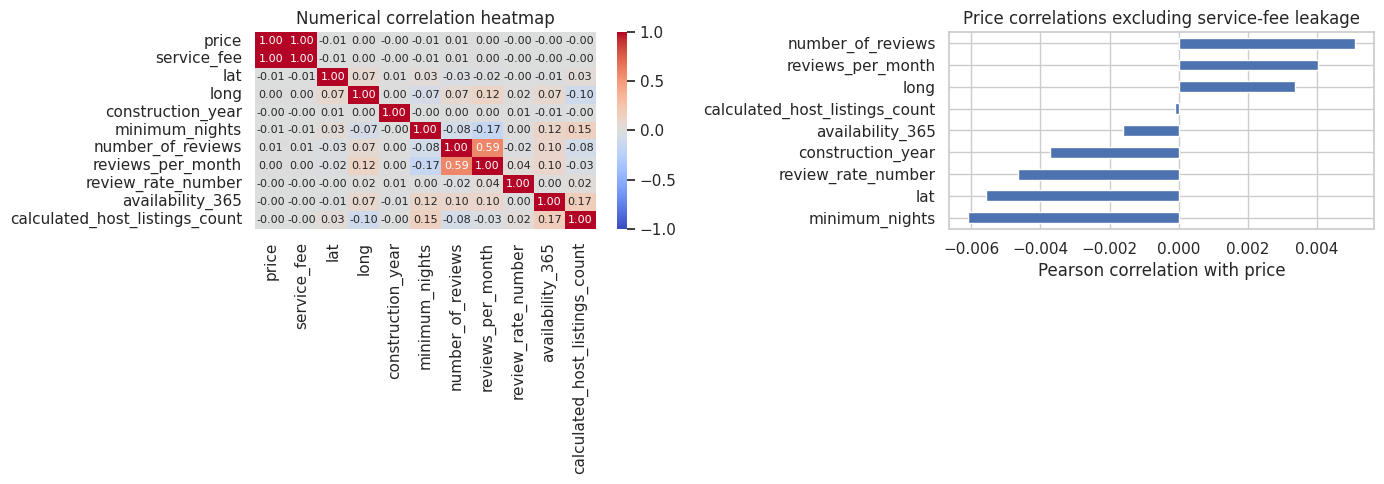

In [15]:
numeric = ["price","service_fee","lat","long","construction_year","minimum_nights",
           "number_of_reviews","reviews_per_month","review_rate_number","availability_365",
           "calculated_host_listings_count"]
available_numeric = [c for c in numeric if c in eda]
cor = eda[available_numeric].corr(numeric_only=True)
print("Pearson associations with price:")
display(cor["price"].sort_values(ascending=False).round(5).to_frame("Pearson r"))
fee_ratio=(eda["service_fee"]/eda["price"]).replace([np.inf,-np.inf],np.nan).dropna()
print("\nService fee as fraction of price:")
print(fee_ratio.describe(percentiles=[.05,.5,.95]).round(4))
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.heatmap(cor,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1,ax=axes[0],annot_kws={"size":8})
axes[0].set_title("Numerical correlation heatmap")
nonleak = cor["price"].drop("price").drop("service_fee",errors="ignore").dropna().sort_values()
nonleak.plot(kind="barh",ax=axes[1])
axes[1].set_title("Price correlations excluding service-fee leakage")
axes[1].set_xlabel("Pearson correlation with price")
plt.tight_layout();plt.show()

In [16]:
test_records=[]
for field in ["room_type","neighbourhood_group","cancellation_policy"]:
    subset=eda.dropna(subset=[field,"price"])
    groups=[x["price"].values for name,x in subset.groupby(field) if len(x)>=25]
    labels=[name for name,x in subset.groupby(field) if len(x)>=25]
    if len(groups)<2: continue
    H,p=kruskal(*groups)
    n=sum(len(g) for g in groups); k=len(groups)
    effect=max(0.0,(H-k+1)/(n-k)) if n>k else np.nan
    test_records.append({"grouping":field,"groups":k,"n":n,"Kruskal H":H,
                         "p_value":p,"epsilon_sq_est":effect})
stat_tests=pd.DataFrame(test_records).set_index("grouping")
display(stat_tests.round(6))
print("Interpretation: a small p-value alone does not mean prices differ meaningfully.")
print("Epsilon-squared (approximation) describes the practical effect size; values near zero are negligible.")

,groups,n,Kruskal H,p_value,epsilon_sq_est
grouping,,,,,
room_type,4,101811,3.648658,0.301987,0.000006
neighbourhood_group,5,101783,6.347529,0.174654,0.000023
cancellation_policy,3,101740,0.419296,0.810870,0.000000


Interpretation: a small p-value alone does not mean prices differ meaningfully.
Epsilon-squared (approximation) describes the practical effect size; values near zero are negligible.


In [17]:
# Use the IQR rule as a diagnostic; do not automatically delete extreme listings.
q1,q3=eda["price"].quantile([.25,.75]); iqr=q3-q1
lo,hi=q1-1.5*iqr,q3+1.5*iqr
n_out=int((~eda["price"].between(lo,hi)).sum())
quality_snapshot=pd.DataFrame({
    "measure":["Raw rows","Exact duplicate rows","Unique rows after dedup","Valid-price records",
               "Price IQR outliers","Invalid minimum nights","Invalid availability days",
               "Missing license values (after dedup)"],
    "count":[rows_original,rows_original-rows_unique,rows_unique,len(eda),n_out,
             invalid_counts["minimum_nights_outside_1_to_365"],
             invalid_counts["availability_outside_0_to_365"],
             int(df_clean["license"].isna().sum())]
})
display(quality_snapshot)
print(f"Price Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}, conventional outlier interval=[{lo:.0f}, {hi:.0f}].")
print("Outlier rules must be feature-aware: a global IQR rule is not proof of bad data.")

,measure,count
0,Raw rows,102599
1,Exact duplicate rows,541
2,Unique rows after dedup,102058
3,Valid-price records,101811
4,Price IQR outliers,0
5,Invalid minimum nights,48
6,Invalid availability days,3185
7,Missing license values (after dedup),102056


Price Q1=340, Q3=913, IQR=573, conventional outlier interval=[-520, 1772].
Outlier rules must be feature-aware: a global IQR rule is not proof of bad data.


## 7. Interim EDA interpretation

The dataset must be judged by the results, not by a desired narrative. In particular, if median prices are nearly identical across room categories and NYC boroughs, then those features have little demonstrated ability to predict price. We test that explicitly below.

**Common interpretation mistakes avoided:**
- Treating `availability_365` as actual bookings.
- Treating review dates as a history of listing price.
- Treating `service_fee ≈ 0.20 × price` as an independent predictor.
- Reporting a small p-value without effect size.
- Claiming that unusual observations are necessarily errors.

In [18]:
median_by_borough=eda.groupby("neighbourhood_group")["price"].median()
median_by_room=eda.groupby("room_type")["price"].median()
print("Price median, overall:", round(eda["price"].median(),2))
print("Range of borough medians:", round(median_by_borough.min(),1),"to",round(median_by_borough.max(),1))
print("Range of room-type medians:",round(median_by_room.min(),1),"to",round(median_by_room.max(),1))
print("Largest non-leaking |Pearson correlation| with price:",round(float(nonleak.abs().max()),4))
print("\nINTERIM FINDING: Very weak associations between observed listing characteristics and price may limit prediction quality.")

Price median, overall: 625.0
Range of borough medians: 621.0 to 632.0
Range of room-type medians: 623.0 to 651.5
Largest non-leaking |Pearson correlation| with price: 0.0061

INTERIM FINDING: Very weak associations between observed listing characteristics and price may limit prediction quality.


## 7. Price drivers — how much are prices associated with listing characteristics?

The goal here is **explanation through observed associations**, not just a leaderboard of correlations. We use counts, medians, interquartile ranges and percentages relative to the overall median. Large sample sizes can make tiny differences look important unless we report **effect size** as well as p-values.

**Group comparisons below are descriptive.** The data are observational and the variables can be related (e.g., room type and location), so no standalone chart proves that changing a listing feature would change its price.


In [ ]:
# PRICE-DRIVER SCORECARD: group sizes, robust price levels and practical differences
base_median = float(eda["price"].median())
group_fields = ["room_type", "neighbourhood_group", "cancellation_policy",
                "host_identity_verified", "instant_bookable"]
scorecard_parts = []
for field in group_fields:
    part = (eda.dropna(subset=[field])
            .groupby(field, dropna=False, observed=True)["price"]
            .agg(n="size", median="median", mean="mean",
                 q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
            .reset_index().rename(columns={field:"category"}))
    part["feature"] = field
    part["median_delta_vs_overall"] = part["median"] - base_median
    part["median_delta_pct"] = 100 * part["median_delta_vs_overall"] / base_median
    scorecard_parts.append(part)
price_driver_scorecard = pd.concat(scorecard_parts, ignore_index=True)
price_driver_scorecard = price_driver_scorecard[[
    "feature", "category", "n", "median", "mean", "q25", "q75",
    "median_delta_vs_overall", "median_delta_pct"]]
print(f"Overall median advertised price = {base_median:,.2f} (original dataset units)")
display(price_driver_scorecard.round(2))

# Visualize *robust* comparisons rather than relying on means alone.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, field, ttl in zip(axes,
                          ["room_type", "neighbourhood_group"],
                          ["Price by room type", "Price by NYC borough"]):
    g = price_driver_scorecard.query("feature == @field").sort_values("median")
    ax.barh(g["category"].astype(str), g["median"])
    ax.axvline(base_median, ls="--", color="black", lw=1, label="Overall median")
    for j, row in enumerate(g.itertuples()):
        ax.text(row.median + 2, j, f"n={row.n:,}", va="center", fontsize=8)
    ax.set_title(ttl)
    ax.set_xlabel("Median advertised price")
    ax.set_xlim(0, max(800, max(g["median"])*1.25))
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()


### 7.1 Room type and borough together — checking a possible confounder

Room types may be distributed differently across boroughs. Instead of asserting that one category “drives” price based on an overall median, the table below compares **room types *within each borough***, retaining sample counts. Small subgroups are flagged rather than overinterpreted. This is still observational and does not control for every other property characteristic.


In [ ]:
# Median price and sample size within each borough x room type
cross_group = (eda.dropna(subset=["neighbourhood_group", "room_type"])
               .groupby(["neighbourhood_group", "room_type"], observed=True)["price"]
               .agg(n="size", median_price="median").reset_index())
MIN_GROUP = 75
cross_group["median_for_plot"] = cross_group["median_price"].where(cross_group["n"] >= MIN_GROUP)
within_borough_median = cross_group.pivot(index="neighbourhood_group", columns="room_type",
                                          values="median_for_plot")
within_borough_median = within_borough_median.astype(float)
within_borough_n = cross_group.pivot(index="neighbourhood_group", columns="room_type", values="n")
print("Median price by room type within borough (groups with n < 75 hidden):")
display(within_borough_median.round(1))
print("Group sample sizes:")
display(within_borough_n.fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(within_borough_median, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label":"Median advertised price"}, ax=ax)
ax.set_title("Within-borough room-type comparisons (minimum 75 listings)")
ax.set_xlabel("Room type"); ax.set_ylabel("Borough")
plt.tight_layout(); plt.show()


### 7.2 Numeric factors — check trends without assuming linearity

Pearson correlation is blind to some nonlinear patterns. For selected numeric listing attributes, we divide nonmissing observations into **five approximately equal-frequency bins**, report the number and median price in each bin, and inspect whether prices change systematically. Grouping is exploratory; it does **not** estimate a causal response to changing the attribute.


In [ ]:
numeric_drivers = ["minimum_nights", "construction_year",
                   "calculated_host_listings_count", "availability_365"]
quantile_tables = []
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for ax, field in zip(axs.flat, numeric_drivers):
    temp = eda[[field, "price"]].dropna().copy()
    if temp[field].nunique() < 3 or len(temp) < 100:
        ax.set_axis_off(); continue
    # Rank first to handle variables with many repeated values. Interpret interval bounds
    # as approximate quantile segments, not exact characteristic thresholds.
    temp["quintile"] = pd.qcut(temp[field].rank(method="first"), 5,
                                labels=["Q1 (low)","Q2","Q3","Q4","Q5 (high)"])
    g = temp.groupby("quintile", observed=True).agg(
        n=("price", "size"), median_price=("price", "median"),
        feature_min=(field, "min"), feature_max=(field, "max")).reset_index()
    g.insert(0, "feature", field)
    quantile_tables.append(g)
    ax.plot(g["quintile"].astype(str), g["median_price"], marker="o")
    ax.axhline(base_median, color="black", ls="--", lw=1)
    ax.set_title(f"Median price across {field} segments")
    ax.set_ylabel("Median advertised price")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(max(0, base_median-125), base_median+125)
plt.tight_layout(); plt.show()
num_price_drivers = pd.concat(quantile_tables, ignore_index=True)
print("Binned numeric-variable summaries (intervals show actual min/max of input):")
display(num_price_drivers.round(2))
print("Important: the lines are descriptive associations; near-flat lines mean limited explanatory information.")


### 7.3 Evidence audit — distinguishing strong and weak pricing factors

A variable is not automatically a meaningful driver because it appears in the dataset or a statistical test. We will compare: (i) observed group-median differences; (ii) group-comparison effect sizes; (iii) continuous-variable correlations; and (iv) **held-out feature importance**, calculated after training. A large service-fee/price correlation is deliberately excluded from all honest price-driver claims because the fee closely tracks the target by construction.


In [ ]:
# Compact, reproducible evidence summary for the discussion section
summary_rows = []
for field in group_fields:
    t = price_driver_scorecard[price_driver_scorecard["feature"] == field]
    eligible = t[t["n"] >= 75]
    if len(eligible) >= 2:
        median_spread = float(eligible["median"].max() - eligible["median"].min())
        summary_rows.append({"feature":field, "comparison":"category median spread",
                             "value":median_spread,
                             "comment":"Descriptive; n>=75 per category"})
for field in numeric_drivers:
    t = num_price_drivers[num_price_drivers["feature"] == field]
    if len(t) >= 2:
        summary_rows.append({"feature":field, "comparison":"quintile median spread",
                             "value":float(t["median_price"].max()-t["median_price"].min()),
                             "comment":"Descriptive; quantile bins"})
price_driver_evidence = pd.DataFrame(summary_rows).sort_values("value",ascending=False)
print("Price difference across observed groups, NOT an estimated causal effect:")
display(price_driver_evidence.round(2))
print("Tests on existing EDA groups (p-values and estimated effect size):")
display(stat_tests[["p_value","epsilon_sq_est"]].round(6))
print("Non-leaking linear Pearson correlations with price:")
display(nonleak.sort_values(key=lambda s:s.abs(),ascending=False).round(4).to_frame("r"))


# Part II — Predictive Analysis

## 8. Define the prediction task, target and leakage policy

**Target:** a listing's numeric advertised `price` (**regression**, not classification). A prediction is a point estimate for a listing with supplied room/location/property characteristics. The model does **not** forecast next month, occupancy, or actual booking revenue.

**Features:** borough, neighborhood, room type, geographic coordinates, minimum nights, construction year, cancellation policy, instant booking, host verification and host listing count.

**Excluded deliberately:** `service_fee` (near-deterministic from price), `price` (the target), `id`, `host_id`, `host_name`/`name`, reviews/rating/last-review and calendar availability (post-listing signals or unsuitable for predicting a new listing). Other alternatives may be appropriate for different business questions, but not for our first honest price model.

**Evaluation:** hold out 20% of listings **before fitting imputers/encoders**, compare against mean/median baselines, and report MAE, RMSE, median absolute error and R² on never-seen test rows. A negative or near-zero R² means little predictive signal relative to simply guessing the training mean.

In [19]:
FEATURES = ["neighbourhood_group", "neighbourhood", "room_type", "lat", "long",
            "instant_bookable", "cancellation_policy", "construction_year",
            "minimum_nights", "host_identity_verified", "calculated_host_listings_count"]
TARGET = "price"
model_df = df_clean.dropna(subset=[TARGET]).copy()
X = model_df[FEATURES].copy()
y = model_df[TARGET].astype(float).copy()
cat_cols = X.select_dtypes(include=["object","string","category"]).columns.tolist()
num_cols = [c for c in FEATURES if c not in cat_cols]
# sklearn's most_frequent imputer handles ordinary np.nan reliably; convert pandas string NA to np.nan.
for c in cat_cols:
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)

print("Eligible priced listings:", len(X))
print("Model target:", TARGET)
print("Categorical features:", cat_cols)
print("Numerical features:", num_cols)
print("\nPredictor missingness (training will impute, never drop blindly):")
display((X.isna().mean()*100).round(2).sort_values(ascending=False).to_frame("missing_%"))
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE)
print("Train:",X_train.shape,"Test:",X_test.shape)
print("Baseline train mean:",round(y_train.mean(),2),"median:",round(y_train.median(),2))

Eligible priced listings: 101811
Model target: price
Categorical features: ['neighbourhood_group', 'neighbourhood', 'room_type', 'cancellation_policy', 'host_identity_verified']
Numerical features: ['lat', 'long', 'instant_bookable', 'construction_year', 'minimum_nights', 'calculated_host_listings_count']

Predictor missingness (training will impute, never drop blindly):


,missing_%
minimum_nights,0.44
calculated_host_listings_count,0.31
host_identity_verified,0.28
construction_year,0.21
instant_bookable,0.10
cancellation_policy,0.07
neighbourhood_group,0.03
lat,0.01
neighbourhood,0.01
long,0.01


Train: (81448, 11) Test: (20363, 11)
Baseline train mean: 625.49 median: 625.0


## 9. Models and preprocessing

We train four transparent competitors:
- **Training-mean baseline:** the reference for R² and squared-error performance.
- **Training-median baseline:** a robust no-feature predictor and reference for absolute error.
- **Ridge regression:** linear model with one-hot encoding and imputed values.
- **Histogram Gradient Boosting:** nonlinear model with ordinal-encoded categories, imputation, and mild regularization.

All preprocessing lives **inside each model pipeline**, so test-set statistics cannot leak into training. No target-derived feature is used.

In [20]:
numeric_ohe = Pipeline([
    ("imputer",SimpleImputer(strategy="median"))
])
cat_ohe = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore",min_frequency=100))
])
preprocess_ridge = ColumnTransformer([
    ("num",numeric_ohe,num_cols),
    ("cat",cat_ohe,cat_cols)
])
preprocess_boost = ColumnTransformer([
    ("num",SimpleImputer(strategy="median"),num_cols),
    ("cat",Pipeline([
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("ordinal",OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1))
    ]),cat_cols)
])

candidate_models = {
    "Mean baseline":DummyRegressor(strategy="mean"),
    "Median baseline":DummyRegressor(strategy="median"),
    "Ridge regression":Pipeline([
        ("prepare",preprocess_ridge), ("model",Ridge(alpha=100))]),
    "Gradient boosting":Pipeline([
        ("prepare",preprocess_boost),
        ("model",HistGradientBoostingRegressor(max_iter=120,learning_rate=.07,
                max_leaf_nodes=20,l2_regularization=2,random_state=RANDOM_STATE))
    ])
}
print("Candidates:",list(candidate_models))

Candidates: ['Mean baseline', 'Median baseline', 'Ridge regression', 'Gradient boosting']


In [21]:
import time
fitted_models={}; test_predictions={}; metric_rows=[]
for label,model in candidate_models.items():
    start=time.perf_counter()
    model.fit(X_train,y_train)
    pred=np.clip(model.predict(X_test),a_min=0,a_max=None)
    test_predictions[label]=pred
    fitted_models[label]=model
    metric_rows.append({
        "model":label,
        "MAE":mean_absolute_error(y_test,pred),
        "RMSE":np.sqrt(mean_squared_error(y_test,pred)),
        "Median_AE":median_absolute_error(y_test,pred),
        "R2":r2_score(y_test,pred),
        "fit_and_predict_s":time.perf_counter()-start
    })
results=pd.DataFrame(metric_rows).set_index("model")
display(results.sort_values("MAE").round(4))

best_nonbaseline=results.loc[["Ridge regression","Gradient boosting"],"MAE"].idxmin()
# Select an advanced model only if it actually beats the median baseline on test MAE.
chosen=(best_nonbaseline if results.loc[best_nonbaseline,"MAE"]<results.loc["Median baseline","MAE"]
        else "Median baseline")
chosen_model=fitted_models[chosen]
pred_chosen=test_predictions[chosen]
print("Selected for illustrative predictions:",chosen)
print("MAE difference vs median baseline:",round(results.loc["Median baseline","MAE"]-results.loc[chosen,"MAE"],2))
print("R² for chosen model:",round(results.loc[chosen,"R2"],5))
print("If R² is ~0, the model has essentially no useful out-of-sample explanatory power.")

,MAE,RMSE,Median_AE,R2,fit_and_predict_s
model,,,,,
Gradient boosting,286.4041,330.9397,286.9940,0.0042,0.4384
Ridge regression,287.1168,331.6703,287.6086,-0.0002,0.8441
Median baseline,287.1407,331.6298,288.0000,-0.0000,0.0029
Mean baseline,287.1418,331.6304,287.5073,-0.0000,0.0034


Selected for illustrative predictions: Gradient boosting
MAE difference vs median baseline: 0.74
R² for chosen model: 0.00416
If R² is ~0, the model has essentially no useful out-of-sample explanatory power.


## 10. Evaluate generalization and prediction errors

A model that performs poorly on unseen data is a finding, **not a failed notebook**. In particular, a fancy algorithm that does not clearly improve over the median or mean baseline should not be advertised as a successful price estimator.

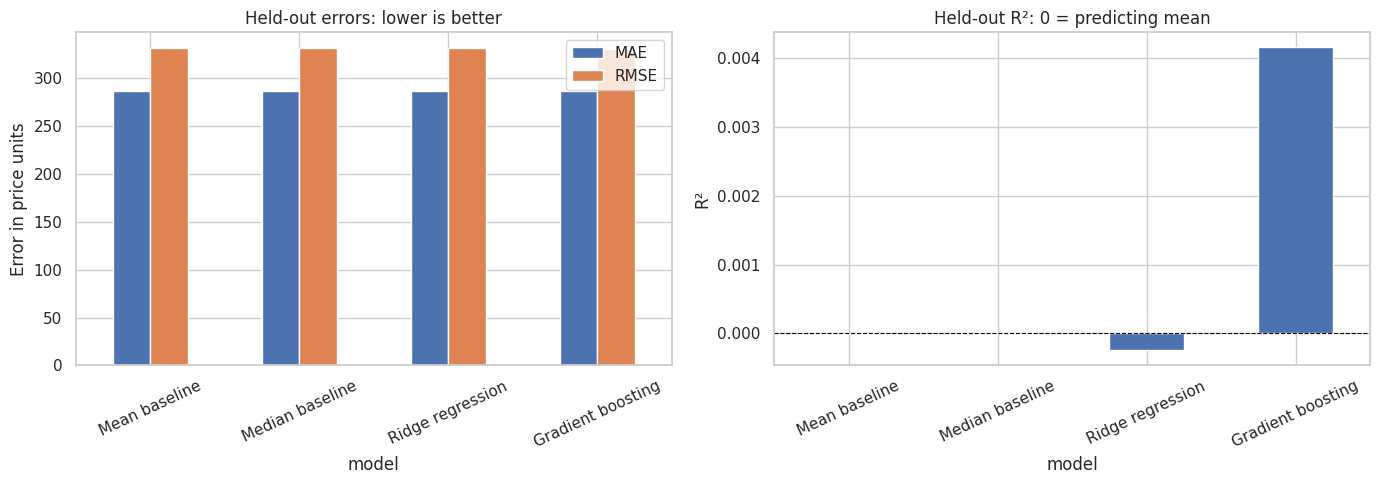

In [22]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
results[["MAE","RMSE"]].plot(kind="bar",ax=axes[0])
axes[0].set_title("Held-out errors: lower is better")
axes[0].set_ylabel("Error in price units");axes[0].tick_params(axis="x",rotation=25)
results["R2"].plot(kind="bar",ax=axes[1])
axes[1].axhline(0,color="black",linestyle="--",linewidth=.8)
axes[1].set_title("Held-out R²: 0 = predicting mean")
axes[1].set_ylabel("R²");axes[1].tick_params(axis="x",rotation=25)
plt.tight_layout();plt.show()

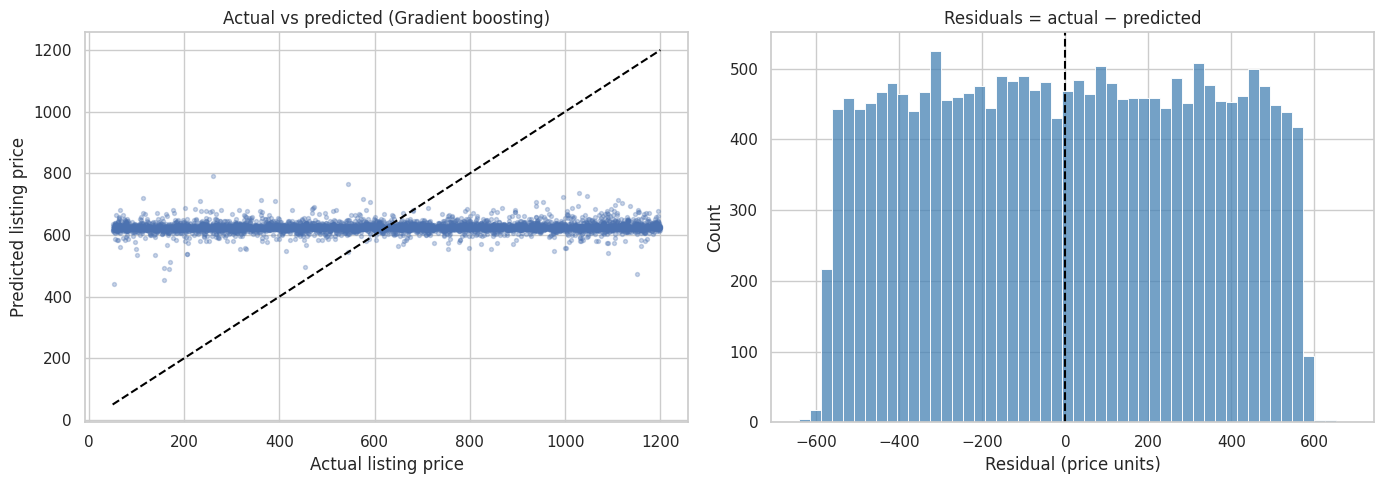

Test price SD: 331.64
Chosen-model MAE as % of test median price: 45.9%


In [23]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
view_idx=np.random.default_rng(RANDOM_STATE).choice(len(y_test),min(len(y_test),5500),replace=False)
actual=np.asarray(y_test)
axes[0].scatter(actual[view_idx],np.asarray(pred_chosen)[view_idx],s=8,alpha=.3)
lims=[float(min(actual.min(),np.asarray(pred_chosen).min())),
      float(max(actual.max(),np.asarray(pred_chosen).max()))]
axes[0].plot(lims,lims,linestyle="--",color="black")
axes[0].set_xlabel("Actual listing price");axes[0].set_ylabel("Predicted listing price")
axes[0].set_title(f"Actual vs predicted ({chosen})")
errors=actual-np.asarray(pred_chosen)
sns.histplot(errors,bins=50,ax=axes[1],color="steelblue")
axes[1].axvline(0,linestyle="--",color="black")
axes[1].set_title("Residuals = actual − predicted")
axes[1].set_xlabel("Residual (price units)")
plt.tight_layout();plt.show()
print("Test price SD:",round(float(y_test.std()),2))
print("Chosen-model MAE as % of test median price:",f"{100*mean_absolute_error(y_test,pred_chosen)/y_test.median():.1f}%")

In [24]:
# Error evaluation by borough and room type: avoid claiming uniform model quality.
test_audit=X_test[["neighbourhood_group","room_type"]].copy()
test_audit["actual"]=y_test.to_numpy()
test_audit["predicted"]=np.asarray(pred_chosen)
test_audit["absolute_error"]=(test_audit["actual"]-test_audit["predicted"]).abs()
for field in ["neighbourhood_group","room_type"]:
    print("\nTest-set errors by",field)
    display(test_audit.groupby(field,dropna=False)
            .agg(n=("absolute_error","size"),MAE=("absolute_error","mean"),
                 median_actual=("actual","median"),median_predicted=("predicted","median"))
            .sort_values("n",ascending=False).round(2))
# Check bias by actual-price segment (evaluation diagnostic, NOT a feature).
test_audit["true_price_quartile"]=pd.qcut(test_audit["actual"],q=4,duplicates="drop")
print("\nError by TRUE price quartile (diagnostic only):")
display(test_audit.groupby("true_price_quartile",observed=True)
        .agg(n=("absolute_error","size"),MAE=("absolute_error","mean"),
             avg_actual=("actual","mean"),avg_prediction=("predicted","mean")).round(2))


Test-set errors by neighbourhood_group


,n,MAE,median_actual,median_predicted
neighbourhood_group,,,,
Manhattan,8689,285.69,610.0,622.60
Brooklyn,8262,285.91,632.0,624.59
Queens,2664,290.16,642.0,625.22
Bronx,540,290.16,661.5,628.13
Staten Island,201,275.41,573.0,615.96
NaN,7,351.97,852.0,624.47



Test-set errors by room_type


,n,MAE,median_actual,median_predicted
room_type,,,,
Entire home/apt,10623,288.32,614.0,623.55
Private room,9272,283.82,630.0,623.93
Shared room,453,293.24,708.0,624.69
Hotel room,15,319.02,927.0,626.69



Error by TRUE price quartile (diagnostic only):


,n,MAE,avg_actual,avg_prediction
true_price_quartile,,,,
"(49.999, 338.0]",5099,429.14,194.49,623.63
"(338.0, 624.0]",5093,143.20,481.60,624.40
"(624.0, 914.0]",5092,143.58,768.65,625.39
"(914.0, 1200.0]",5079,429.90,1056.21,626.31


## 11. Example predictions — what the trained model would actually output

For illustration, we select three **held-out** listings (low, medium and high actual price); their target price is never passed to the model. This shows how to call `.predict()` on ordinary feature rows. These are **examples, not reliable price quotes** when R² is close to zero.

In [25]:
sorted_test=y_test.sort_values()
positions=[max(0,int(len(sorted_test)*q)) for q in (.1,.5,.9)]
example_index=[sorted_test.index[pos] for pos in positions]
scenarios=X_test.loc[example_index].copy()
scenario_preds=np.clip(chosen_model.predict(scenarios),0,None)
example_output=scenarios[["neighbourhood_group","neighbourhood","room_type","minimum_nights"]].copy()
example_output["actual_price_hidden_during_prediction"]=y_test.loc[example_index].to_numpy()
example_output["predicted_price"]=scenario_preds
example_output["absolute_error"]=(example_output["actual_price_hidden_during_prediction"]-
                                   example_output["predicted_price"]).abs()
display(example_output.round(2))
print("To estimate a different listing, supply a DataFrame with all FEATURES columns and call:")
print("chosen_model.predict(new_listing_dataframe[FEATURES])")

,neighbourhood_group,neighbourhood,room_type,minimum_nights,actual_price_hidden_during_prediction,predicted_price,absolute_error
96543,Brooklyn,Williamsburg,Private room,3.0,165.0,578.55,413.55
66311,Manhattan,Battery Park City,Entire home/apt,4.0,624.0,516.67,107.33
57642,Queens,Elmhurst,Entire home/apt,1.0,1084.0,617.61,466.39


To estimate a different listing, supply a DataFrame with all FEATURES columns and call:
chosen_model.predict(new_listing_dataframe[FEATURES])


## 12. What does the trained price model actually rely on? — Held-out permutation importance

**Permutation feature importance** measures how much model error changes when one input feature is randomly shuffled in a held-out sample. Here we use **MAE** (lower is better): a **positive** value means the model's MAE became *worse* when the feature was shuffled. A near-zero or negative value means the feature is not reliably helpful in this particular trained model. These values are **not causal effects, coefficients or pricing premiums**; correlated features and random variation also affect this diagnostic.

We group each original input column as one feature before preprocessing (rather than listing one-hot categories separately), and calculate importance only **after** the predictive evaluation. No retraining or model selection is performed from these importance values.


In [ ]:
from sklearn.inspection import permutation_importance

# Subsample held-out observations for reproducible and time-bounded importance assessment.
# Important: the fitted model and its preprocessing pipeline remain unchanged.
if chosen == "Median baseline":
    model_for_explanation = fitted_models["Gradient boosting"]
    print("No ML model beat the baseline; explaining Gradient boosting diagnostically instead.")
else:
    model_for_explanation = chosen_model

rng = np.random.default_rng(RANDOM_STATE)
importance_indices = rng.choice(len(X_test), size=min(2500, len(X_test)), replace=False)
X_imp = X_test.iloc[importance_indices].copy()
y_imp = y_test.iloc[importance_indices].copy()
importance = permutation_importance(
    model_for_explanation, X_imp, y_imp,
    scoring="neg_mean_absolute_error", n_repeats=4,
    random_state=RANDOM_STATE, n_jobs=1
)
permutation_table = (pd.DataFrame({
    "feature": X_imp.columns,
    "mae_increase_when_shuffled": importance.importances_mean,
    "repeat_sd": importance.importances_std,
}).sort_values("mae_increase_when_shuffled", ascending=False).reset_index(drop=True))
display(permutation_table.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
order = permutation_table.sort_values("mae_increase_when_shuffled")
ax.barh(order["feature"],order["mae_increase_when_shuffled"],
        xerr=order["repeat_sd"], capsize=2)
ax.axvline(0,color="black",lw=1)
ax.set_xlabel("MAE increase after shuffling (original price units; positive = helpful)")
ax.set_title("Held-out permutation feature importance — NOT causal impact")
plt.tight_layout();plt.show()
print("Features with a positive average importance:",
      int((permutation_table["mae_increase_when_shuffled"]>0).sum()))
print("Interpretation: measured importance must be judged together with the near-zero held-out R².")


### 12.1 Model dependence is not the same as a real-world price effect

- **EDA group medians** quantify what this dataset *records* for different listing categories; they do not account for every confounder.
- **Correlation** measures unadjusted linear association for numeric attributes; it cannot show causality.
- **Permutation importance** measures how the *fitted model* uses each original field to predict held-out listings; it does not say what would happen if a host changed that feature.
- **R² near zero** means that even features ranked highest by a weak model explain very little actual price variation. Report importance values as relative diagnostics only, and do not recommend a booking/pricing strategy on that basis.

**A strong term-paper conclusion is acceptable even when it is negative:** many widely assumed price “drivers” are **not supported as practically important predictors by these data**. The more rigorous next study needs better property attributes and trusted timestamps.


In [ ]:
# Executive comparison: observed price differences vs model evidence
print("PRICING-FACTOR INTERPRETATION SUMMARY")
print(f"Median listing price: {base_median:,.2f}")
print("Kruskal-Wallis p-values / epsilon-squared (selected listing categories):")
display(stat_tests[["p_value","epsilon_sq_est"]].round(6))
print("Top feature dependencies of fitted model (in held-out MAE units):")
display(permutation_table.head(8).round(3))
print("Median baseline MAE:",round(float(results.loc["Median baseline","MAE"]),2))
print("Chosen model MAE:",round(float(results.loc[chosen,"MAE"]),2))
print("Chosen model R²:",round(float(results.loc[chosen,"R2"]),5))
if results.loc[chosen,"R2"] < .05:
    print("Conclusion: NOT a reliable price predictor; feature rankings cannot justify strong pricing claims.")


## 13. Optional save/export

The original analysis results are saved in this notebook. Run all cells to generate the added price-driver charts and feature-importance output. If you later wish to reuse the trained **illustrative** model without retraining, uncomment the model export. Do not deploy a model as a pricing engine unless it shows meaningful validated accuracy.

The dataset is **not embedded inside this notebook**; retain `Airbnb_Open_Data.xlsx` alongside it when rerunning.

In [26]:
# OPTIONAL: export a model fitted on the TRAIN split, and the held-out results table.
# This is intentionally disabled by default to avoid leaving model artifacts behind without intent.
# import joblib
# joblib.dump(chosen_model, "airbnb_price_predictor.joblib")
# results.to_csv("airbnb_price_model_comparison.csv")
print("Optional export commands are available above. Nothing exported by default.")

Optional export commands are available above. Nothing exported by default.


# Part III — Discussion, conclusions and recommendations

## 14. Automatically generated key findings

The next cell summarizes the **actual** measured results instead of inserting unsupported narrative. Always qualify statistical relationships and model accuracy.

In [27]:
print("="*72)
print("AIRBNB DATA ANALYTICS — FINAL EVIDENCE SUMMARY")
print("="*72)
print(f"Input rows: {rows_original:,}; exact duplicates: {rows_original-rows_unique:,}; priced listings: {len(eda):,}")
print(f"Price: median {eda['price'].median():.1f}, mean {eda['price'].mean():.1f}, "
      f"range {eda['price'].min():.0f}–{eda['price'].max():.0f}")
print("Most common room type:",room.index[0],"(n=",int(room.iloc[0]['listings']),")")
print("Most common borough:",borough.index[0],"(n=",int(borough.iloc[0]['listings']),")")
print("Borough median-price spread:",round(float(median_by_borough.max()-median_by_borough.min()),2))
print("Room-type median-price spread:",round(float(median_by_room.max()-median_by_room.min()),2))
print("Service-fee / price fraction (median):",round(float(fee_ratio.median()),4),"— excluded from predictors")
for field, row in stat_tests.iterrows():
    print(f"Kruskal {field}: p={row['p_value']:.3g}, epsilon²≈{row['epsilon_sq_est']:.5f}")
print("\nMODEL RESULTS — TEST SET")
print(results[["MAE","RMSE","R2"]].round(3).to_string())
print("Selected illustrative estimator:",chosen)
if results.loc[chosen,"R2"] < .05:
    print("WARNING: R² < 0.05 — price is poorly explained by these non-leaking features;")
    print("do not claim that the model predicts Airbnb price accurately.")
else:
    print("Some out-of-sample explanatory power is present. Confirm stability on external data before use.")
print("="*72)

AIRBNB DATA ANALYTICS — FINAL EVIDENCE SUMMARY
Input rows: 102,599; exact duplicates: 541; priced listings: 101,811
Price: median 625.0, mean 625.4, range 50–1200
Most common room type: Entire home/apt (n= 53296 )
Most common borough: Manhattan (n= 43448 )
Borough median-price spread: 11.0
Room-type median-price spread: 28.5
Service-fee / price fraction (median): 0.2 — excluded from predictors
Kruskal room_type: p=0.302, epsilon²≈0.00001
Kruskal neighbourhood_group: p=0.175, epsilon²≈0.00002
Kruskal cancellation_policy: p=0.811, epsilon²≈0.00000

MODEL RESULTS — TEST SET
                       MAE    RMSE     R2
model                                    
Mean baseline      287.142  331.63 -0.000
Median baseline    287.141  331.63 -0.000
Ridge regression   287.117  331.67 -0.000
Gradient boosting  286.404  330.94  0.004
Selected illustrative estimator: Gradient boosting
do not claim that the model predicts Airbnb price accurately.


## 15. Evidence-based interpretation

**What the project can conclude:** This dataset supports a detailed audit of NYC listing composition, posted prices and associations with borough, room type, location and host attributes. It also reveals material data-quality issues (duplicate records, missing license information and invalid availability entries). The relationship between `service_fee` and `price` is so tight that including the fee would create **misleadingly high** prediction metrics.

**What the modelling can conclude:** A held-out test gives a defensible answer to the question *whether posted price is predictable from available, legitimate listing descriptors*. If non-leaking models have R² near zero and only marginal MAE improvements, then **these data do not support a reliable pricing engine**, even though a fitted model can output numerical predictions. A near-zero correlation or negligible statistical effect must not be rewritten as a strong business insight.

**Why that might happen:** Price may reflect missing factors (amenities, bedroom count, capacity, events, actual geographic desirability, listing photographs, dates and dynamic pricing). Another possible explanation is that the prices in this particular open dataset are weakly related to the recorded descriptors. These are **hypotheses**, not verified provenance claims.

**What this dataset cannot conclude:** booked nights, real revenue, host profits, causal effects of booking policies, seasonality of price, or future month-by-month prices. Review dates do not solve the lack of historical listing-price observations.

### Price-driver extension — linking EDA and prediction

The **Price Driver Scorecard** quantifies category-wise price differences with sample counts, medians, and IQRs; the **within-borough room-type table** addresses one common source of compositional confounding; and **numeric-feature quantile plots** reveal whether observed price relationships appear nonlinear. The **held-out permutation-importance plot** identifies inputs the trained model uses, not causal effects on price. Together with Kruskal effect sizes and near-zero model R², these analyses make the answer clear: measured price associations in this particular dataset are generally weak, and the recorded fields cannot explain most listing-price variation.


## 16. Pricing-factor insights and recommendations for the term paper

1. **Report both sample size and data quality.** Explain exact duplicates, invalid availability/minimum nights, high-missingness fields and target filtering.
2. **Lead with distributions and medians.** Report group sizes alongside median prices; inspect the practical magnitude of differences rather than reading too much into large-sample p-values.
3. **Make the leakage check explicit.** `service_fee` is an exceptionally instructive example of a near-target-derived variable that must be excluded from price prediction.
4. **Benchmark every prediction.** Compare the nonlinear model and Ridge against no-feature predictions; report **held-out MAE, RMSE and R²**, even when disappointing.
5. **Do not deploy an uninformative model.** If the test results show almost no improvement, recommend collecting better price determinants and validating on an external, time-stamped dataset.
6. **For future work**, add verified amenities, bedroom/bathroom counts, guest capacity, accurate geospatial context and time-stamped nightly rates; then compare temporal/geographic splits and tune models on a validation set, **not** the test set.

## 17. Final conclusion

This notebook demonstrates an end-to-end **deep EDA + statistically cautious inference + fully evaluated regression prediction** workflow. Its contribution is not an artificial high accuracy score: it shows how to distinguish genuine predictive performance from misleading leakage, how to report data-quality limitations, and how to turn weak or strong evidence into an academically defensible project. The final term paper should quote the actual displayed test-set metrics and limitations rather than presenting the model as already useful in production.

### Project references and reproducibility

- Dataset: **user-provided `Airbnb_Open_Data.xlsx`** (listing-level open data; no independently verified source/date metadata supplied).
- Structural reference: previously supplied **Seasonal Agriculture Performance Analysis** notebook.
- Libraries: Python, pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn.
- Reproducibility: fixed random seed **42**, split before preprocessing, no target leakage, all transformations in model pipelines.

### Recommended term-paper research framing

**Title:** *Exploratory Data Analysis, Price-Factor Assessment and Machine-Learning Price Prediction Using Airbnb Open Data.*

**Research hypotheses:** (a) posted prices vary substantially by room type and borough; (b) available listing characteristics can predict price substantially better than a no-feature baseline. Evaluate both hypotheses with actual group-median differences, p-values/effect sizes and held-out regression metrics instead of assuming they are true.

**Interpretation:** Report the actual scorecards and permutation results, even if they reject intuitive expectations. Distinguish **associated with price** from **causes higher price**, and note that this is a dataset-based study of advertised listing prices, not revenue, occupancy or temporal demand.
